# Étape 6 — Amélioration du modèle

**Termes techniques :** configuration, Dropout, learning rate, EarlyStopping, validation, comparaison, généralisation

## Données et modèle de référence

In [1]:
import sys
import time
from pathlib import Path
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
while PROJECT_DIR != PROJECT_DIR.parent and not (PROJECT_DIR / "data" / "split" / "train.csv").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
SPLIT_DIR = PROJECT_DIR / "data" / "split"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
from src.data_pipeline import load_manifest, make_augmentation

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42
MAX_EPOCHS = 20

train_table = pd.read_csv(SPLIT_DIR / "train.csv")
class_names = sorted(train_table["label"].unique())
class_to_id = {name: index for index, name in enumerate(class_names)}
train_ds = load_manifest(SPLIT_DIR / "train.csv", class_to_id, IMG_SIZE, BATCH_SIZE, shuffle=True, seed=SEED)
val_ds = load_manifest(SPLIT_DIR / "validation.csv", class_to_id, IMG_SIZE, BATCH_SIZE)
augmentation = make_augmentation(SEED)
train_ds = train_ds.map(lambda images, labels: (augmentation(images, training=True), labels))
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

BASE_MODEL_PATH = MODEL_DIR / "cnn_scenevision.keras"
reference_model = tf.keras.models.load_model(BASE_MODEL_PATH)
reference_loss, reference_accuracy = reference_model.evaluate(val_ds, verbose=0)
print("Images train :", len(train_table))
print("Accuracy validation de référence :", round(reference_accuracy, 4))
print("Loss validation de référence :", round(reference_loss, 4))

Images train : 11923
Accuracy validation de référence : 0.8607
Loss validation de référence : 0.3968


## Configurations testées

In [2]:
def build_model(dropout_rate, learning_rate):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(150, 150, 3)),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(2, 2),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(2, 2),
        tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(2, 2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(len(class_names), activation="softmax"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

configurations = [
    {"name": "Dropout 0.5", "dropout": 0.5, "learning_rate": 0.001},
    {"name": "Learning rate 0.0005", "dropout": 0.4, "learning_rate": 0.0005},
]
results = [{
    "configuration": "Référence (Dropout 0.4, Adam 0.001)",
    "dropout": 0.4,
    "learning_rate": 0.001,
    "epochs": 20,
    "validation_loss": float(reference_loss),
    "validation_accuracy": float(reference_accuracy),
    "training_seconds": None,
}]
best_validation_loss = float(reference_loss)
best_model_name = "Référence"
best_model = reference_model

## Entraîner et comparer

In [3]:
for config in configurations:
    model = build_model(config["dropout"], config["learning_rate"])
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    )

    start_time = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=MAX_EPOCHS,
        callbacks=[early_stop, reduce_lr],
        shuffle=False,
        verbose=2,
    )
    training_seconds = time.perf_counter() - start_time
    validation_loss, validation_accuracy = model.evaluate(val_ds, verbose=0)

    results.append({
        "configuration": config["name"],
        "dropout": config["dropout"],
        "learning_rate": config["learning_rate"],
        "epochs": len(history.history["loss"]),
        "validation_loss": float(validation_loss),
        "validation_accuracy": float(validation_accuracy),
        "training_seconds": round(training_seconds, 1),
    })

    if validation_loss < best_validation_loss:
        best_validation_loss = float(validation_loss)
        best_model_name = config["name"]
        best_model = model

SELECTED_MODEL_PATH = MODEL_DIR / "cnn_scenevision_selected.keras"
best_model.save(SELECTED_MODEL_PATH)
best_model_path = SELECTED_MODEL_PATH
comparison = pd.DataFrame(results).sort_values("validation_loss")
display(comparison)
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print("Meilleure configuration sur validation :", best_model_name)
print("Modèle à évaluer ensuite :", best_model_path)

Epoch 1/20
373/373 - 108s - 290ms/step - accuracy: 0.5611 - loss: 1.1255 - val_accuracy: 0.6826 - val_loss: 0.8308 - learning_rate: 0.0010
Epoch 2/20
373/373 - 127s - 342ms/step - accuracy: 0.6602 - loss: 0.9011 - val_accuracy: 0.7499 - val_loss: 0.6655 - learning_rate: 0.0010
Epoch 3/20
373/373 - 107s - 287ms/step - accuracy: 0.7239 - loss: 0.7744 - val_accuracy: 0.7855 - val_loss: 0.5775 - learning_rate: 0.0010
Epoch 4/20
373/373 - 108s - 291ms/step - accuracy: 0.7485 - loss: 0.7197 - val_accuracy: 0.8031 - val_loss: 0.5486 - learning_rate: 0.0010
Epoch 5/20
373/373 - 108s - 290ms/step - accuracy: 0.7663 - loss: 0.6709 - val_accuracy: 0.8047 - val_loss: 0.5224 - learning_rate: 0.0010
Epoch 6/20
373/373 - 107s - 287ms/step - accuracy: 0.7763 - loss: 0.6266 - val_accuracy: 0.8192 - val_loss: 0.5087 - learning_rate: 0.0010
Epoch 7/20
373/373 - 109s - 292ms/step - accuracy: 0.7946 - loss: 0.5908 - val_accuracy: 0.8192 - val_loss: 0.5177 - learning_rate: 0.0010
Epoch 8/20
373/373 - 138s -

,configuration,dropout,learning_rate,epochs,validation_loss,validation_accuracy,training_seconds
1,Dropout 0.5,0.5,0.0010,16,0.388216,0.861057,2161.0
0,"Référence (Dropout 0.4, Adam 0.001)",0.4,0.0010,20,0.396830,0.860665,NaN
2,Learning rate 0.0005,0.4,0.0005,16,0.396850,0.856751,2281.3


Meilleure configuration sur validation : Dropout 0.5
Modèle à évaluer ensuite : c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision_selected.keras


## Courbes de comparaison

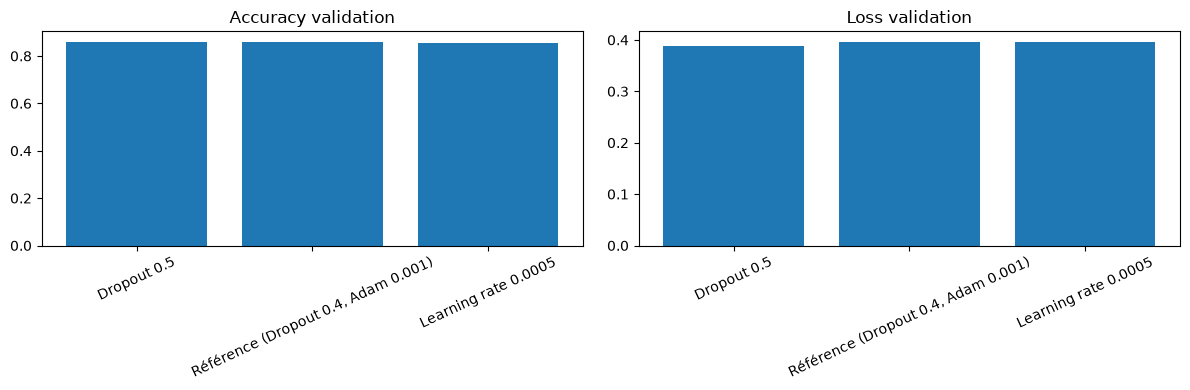

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison["configuration"], comparison["validation_accuracy"])
axes[0].set_title("Accuracy validation")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(comparison["configuration"], comparison["validation_loss"])
axes[1].set_title("Loss validation")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## Modèle retenu

In [5]:
print("Configuration retenue :", best_model_name)
print("Loss validation :", round(best_validation_loss, 4))
print("Fichier du modèle :", best_model_path)
print("Résultats enregistrés dans :", RESULTS_DIR / "model_comparison.csv")

Configuration retenue : Dropout 0.5
Loss validation : 0.3882
Fichier du modèle : c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\models\cnn_scenevision_selected.keras
Résultats enregistrés dans : c:\Users\Olaya\Desktop\sprint_2\SceneVision AI\results\model_comparison.csv


## Évaluation finale

**Termes techniques :** jeu de test, Accuracy, Precision, Recall, F1-score, matrice de confusion